In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'/kaggle/input/datasets/hemantbisht9/fulllllll/bank-additional-full.csv', sep=";")

In [3]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [5]:
df.shape

(41188, 21)

In [6]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(12)

In [8]:
df=df.drop_duplicates()

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.columns.tolist()

['age',
 'job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed',
 'y']

In [11]:
df['y'].value_counts()

y
no     36537
yes     4639
Name: count, dtype: int64

In [12]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [13]:
df['job'].value_counts()

job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

In [14]:
ct = pd.crosstab(df['job'],df['y'])

In [15]:
from scipy.stats import chi2_contingency
chi2 , p, dof,exp = chi2_contingency(ct)
alpha = 0.05
if p>alpha:
    print("null accpected there is no relationship between features.")
else:
    print("There is the relationship between them.")
print("p_value:",p)

There is the relationship between them.
p_value: 3.2684116066165443e-199


In [16]:
ct.values.sum()

np.int64(41176)

In [17]:
df['marital'].value_counts()

marital
married     24921
single      11564
divorced     4611
unknown        80
Name: count, dtype: int64

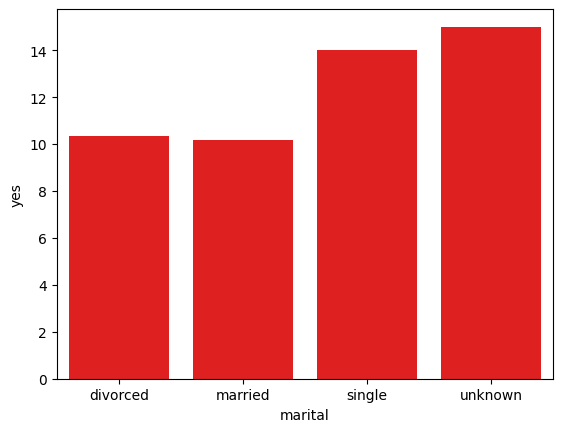

In [18]:
marital_col= pd.crosstab(df['marital'],df['y'],normalize='index')*100
sns.barplot(x=marital_col.index,y=marital_col['yes'],color='red')
plt.ylabel=('yes rate')

In [19]:
marital_col2= pd.crosstab(df['marital'],df['y'])
chi2 , p, dof,exp = chi2_contingency(marital_col2)
alpha = 0.05
if p>alpha:
    print("null accpected there is no relationship between features.")
else:
    print("There is the relationship between them.")
print("p_value:",p)

There is the relationship between them.
p_value: 1.7784225004611415e-26


In [20]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [21]:
cat_col = df.select_dtypes(include='object').columns.drop('y')
rows=[]
for col in cat_col:
    ct3 = pd.crosstab(df[col],df['y'])
    chi2,p,dof,exp= chi2_contingency(ct3)
    rows.append([col,chi2,p,dof])
    res= pd.DataFrame(rows,columns=['features','Chi2','p','dof'])
    res['Relationship']= res['p'].apply(lambda x:'yes'if x<0.05 else 'no')
print(res)

      features         Chi2              p  dof Relationship
0          job   961.743804  3.268412e-199   11          yes
1      marital   122.959314   1.778423e-26    3          yes
2    education   192.848505   3.746768e-38    7          yes
3      default   406.556094   5.217541e-89    2          yes
4      housing     5.742153   5.663793e-02    2           no
5         loan     1.099295   5.771532e-01    2           no
6      contact   862.080737  1.718741e-189    1          yes
7        month  3103.032672   0.000000e+00    9          yes
8  day_of_week    26.054244   3.085755e-05    4          yes
9     poutcome  4230.143428   0.000000e+00    2          yes


In [22]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [23]:
df['y'].unique()

array(['no', 'yes'], dtype=object)

In [24]:
num_col=['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed','y']

In [25]:
num_col

['age',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed',
 'y']

In [26]:
df['y']=df['y'].map({'no':0,'yes':1})

In [27]:
df['y'].value_counts()

y
0    36537
1     4639
Name: count, dtype: int64

In [28]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0


<Axes: >

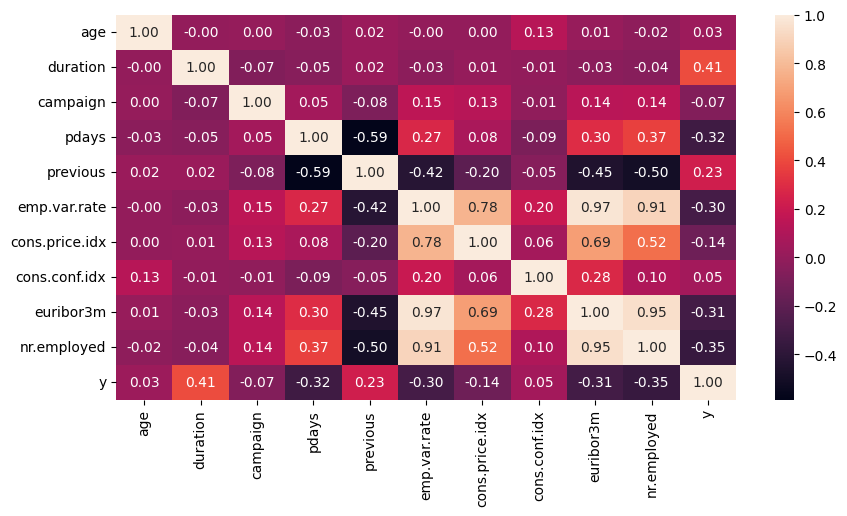

In [29]:
plt.figure(figsize=(10,5))
sns.heatmap(df[num_col].corr(),annot=True,fmt='.2f')

In [30]:
cat_col

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='object')

In [31]:
df[cat_col].head()

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome
0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,nonexistent
1,services,married,high.school,unknown,no,no,telephone,may,mon,nonexistent
2,services,married,high.school,no,yes,no,telephone,may,mon,nonexistent
3,admin.,married,basic.6y,no,no,no,telephone,may,mon,nonexistent
4,services,married,high.school,no,no,yes,telephone,may,mon,nonexistent


In [32]:
df['education'].value_counts()

education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64

In [33]:
df['education'].unique()

array(['basic.4y', 'high.school', 'basic.6y', 'basic.9y',
       'professional.course', 'unknown', 'university.degree',
       'illiterate'], dtype=object)

In [34]:
df["education"]= df["education"].map({'basic.4y':1, 'high.school':4, 'basic.6y':2, 'basic.9y':3,
       'professional.course':5, 'unknown':-1, 'university.degree':6,
       'illiterate':0})

In [35]:
df["education"].value_counts()

education
 6    12164
 4     9512
 3     6045
 5     5240
 1     4176
 2     2291
-1     1730
 0       18
Name: count, dtype: int64

In [36]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,1,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
1,57,services,married,4,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
2,37,services,married,4,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
3,40,admin.,married,2,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
4,56,services,married,4,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0


In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41176 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41176 non-null  int64  
 1   job             41176 non-null  object 
 2   marital         41176 non-null  object 
 3   education       41176 non-null  int64  
 4   default         41176 non-null  object 
 5   housing         41176 non-null  object 
 6   loan            41176 non-null  object 
 7   contact         41176 non-null  object 
 8   month           41176 non-null  object 
 9   day_of_week     41176 non-null  object 
 10  duration        41176 non-null  int64  
 11  campaign        41176 non-null  int64  
 12  pdays           41176 non-null  int64  
 13  previous        41176 non-null  int64  
 14  poutcome        41176 non-null  object 
 15  emp.var.rate    41176 non-null  float64
 16  cons.price.idx  41176 non-null  float64
 17  cons.conf.idx   41176 non-null  floa

In [38]:
obj_col=df.select_dtypes(include='object').columns
df = pd.get_dummies(df,columns=obj_col,drop_first=True)

In [39]:
df

,age,education,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56,1,261,1,999,0,1.1,93.994,-36.4,4.857,...,True,False,False,False,True,False,False,False,True,False
1,57,4,149,1,999,0,1.1,93.994,-36.4,4.857,...,True,False,False,False,True,False,False,False,True,False
2,37,4,226,1,999,0,1.1,93.994,-36.4,4.857,...,True,False,False,False,True,False,False,False,True,False
3,40,2,151,1,999,0,1.1,93.994,-36.4,4.857,...,True,False,False,False,True,False,False,False,True,False
4,56,4,307,1,999,0,1.1,93.994,-36.4,4.857,...,True,False,False,False,True,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,5,334,1,999,0,-1.1,94.767,-50.8,1.028,...,False,True,False,False,False,False,False,False,True,False
41184,46,5,383,1,999,0,-1.1,94.767,-50.8,1.028,...,False,True,False,False,False,False,False,False,True,False
41185,56,6,189,2,999,0,-1.1,94.767,-50.8,1.028,...,False,True,False,False,False,False,False,False,True,False
41186,44,5,442,1,999,0,-1.1,94.767,-50.8,1.028,...,False,True,False,False,False,False,False,False,True,False


In [40]:
bool_col=df.select_dtypes(include='bool').columns
df[bool_col]=df[bool_col].astype(int)

In [41]:
df.head()

,age,education,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56,1,261,1,999,0,1.1,93.994,-36.4,4.857,...,1,0,0,0,1,0,0,0,1,0
1,57,4,149,1,999,0,1.1,93.994,-36.4,4.857,...,1,0,0,0,1,0,0,0,1,0
2,37,4,226,1,999,0,1.1,93.994,-36.4,4.857,...,1,0,0,0,1,0,0,0,1,0
3,40,2,151,1,999,0,1.1,93.994,-36.4,4.857,...,1,0,0,0,1,0,0,0,1,0
4,56,4,307,1,999,0,1.1,93.994,-36.4,4.857,...,1,0,0,0,1,0,0,0,1,0


In [42]:
x= df.drop(columns=['y','duration'])
y= df['y']

In [43]:
x

,age,education,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56,1,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,1,0,0,0,1,0,0,0,1,0
1,57,4,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,1,0,0,0,1,0,0,0,1,0
2,37,4,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,1,0,0,0,1,0,0,0,1,0
3,40,2,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,1,0,0,0,1,0,0,0,1,0
4,56,4,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,1,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,5,1,999,0,-1.1,94.767,-50.8,1.028,4963.6,...,0,1,0,0,0,0,0,0,1,0
41184,46,5,1,999,0,-1.1,94.767,-50.8,1.028,4963.6,...,0,1,0,0,0,0,0,0,1,0
41185,56,6,2,999,0,-1.1,94.767,-50.8,1.028,4963.6,...,0,1,0,0,0,0,0,0,1,0
41186,44,5,1,999,0,-1.1,94.767,-50.8,1.028,4963.6,...,0,1,0,0,0,0,0,0,1,0


In [44]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve)
import warnings
warnings.filterwarnings("ignore")

In [45]:
x_train , x_test , y_train , y_test=train_test_split(x,y,test_size=0.2,random_state=42) 

In [46]:
scaler = StandardScaler()
x_train_scale=scaler.fit_transform(x_train)
x_test_scale=scaler.transform(x_test)

In [47]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced",max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced",random_state=42),
    "Random Forest": RandomForestClassifier(class_weight="balanced",random_state=42),
    "SVM": SVC(class_weight="balanced"),
    "Naive Bayes": GaussianNB(),
}

results = {}

for name, model in models.items():
    model.fit(x_train_scale, y_train)

    train_acc = accuracy_score(y_train, model.predict(x_train_scale))
    test_acc = accuracy_score(y_test, model.predict(x_test_scale))
    results[name] = {"Train Acc": train_acc, "Test Acc": test_acc}

    print(f"\n{name}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Test Accuracy:  {test_acc:.4f}")
    print(classification_report(y_test, model.predict(x_test_scale)))


Logistic Regression
Train Accuracy: 0.8298
Test Accuracy:  0.8241
              precision    recall  f1-score   support

           0       0.94      0.85      0.90      7265
           1       0.36      0.63      0.46       971

    accuracy                           0.82      8236
   macro avg       0.65      0.74      0.68      8236
weighted avg       0.88      0.82      0.84      8236


KNN
Train Accuracy: 0.9145
Test Accuracy:  0.8856
              precision    recall  f1-score   support

           0       0.91      0.97      0.94      7265
           1       0.53      0.27      0.36       971

    accuracy                           0.89      8236
   macro avg       0.72      0.62      0.65      8236
weighted avg       0.86      0.89      0.87      8236


Decision Tree
Train Accuracy: 0.9942
Test Accuracy:  0.8396
              precision    recall  f1-score   support

           0       0.91      0.91      0.91      7265
           1       0.33      0.34      0.33       971

   

In [48]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

hgb = HistGradientBoostingClassifier(class_weight="balanced", random_state=42)
search = RandomizedSearchCV(
    hgb,
    {"learning_rate": [0.03, 0.05, 0.1],
     "max_depth": [3, 5, 7],
     "max_leaf_nodes": [15, 31],
     "min_samples_leaf": [20, 50, 100],
     "l2_regularization": [0, 1, 5]},
    n_iter=15, scoring="roc_auc",
    cv=StratifiedKFold(3, shuffle=True, random_state=42),
    n_jobs=-1, random_state=42,
)
search.fit(x_train_scale, y_train)   # encoded X (one-hot ya pipeline ke andar)
print(search.best_params_, search.best_score_)

{'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_depth': 5, 'learning_rate': 0.05, 'l2_regularization': 0} 0.8041322771343239


In [49]:
best_hgb = search.best_estimator_

y_pred = best_hgb.predict(x_test_scale)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

score = best_hgb.decision_function(x_test_scale)
print("F1 (class 1):", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, score), 3))

              precision    recall  f1-score   support

           0       0.95      0.85      0.90      7265
           1       0.37      0.65      0.47       971

    accuracy                           0.83      8236
   macro avg       0.66      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236

[[6198 1067]
 [ 343  628]]
F1 (class 1): 0.471
ROC-AUC: 0.803
